# Adding a systematic

This notebook adds a systematic to SBM step by step: an error $\delta$ on the
polarization angle of the detector. It is the procedure of the documentation page
*Adding a systematic*, and its result is `sbm.systematics.polarization_angle`.

A systematic is a function that returns the **perturbation** of the data of a
detector as spin components (a `SignalModel`); it knows neither the scan nor the
map-maker. The data are written as

$$d = \sum_{n,m} {}_{n,m}\tilde S\, e^{i(n\psi + m\phi)},$$

with the crossing angle $\psi$ and the HWP angle $\phi$. An ideal detector without HWP
sees $I$ at $(0,0)$ and $P/2$ at $(2,0)$ ($P = Q + iU$); behind a HWP, $P/2$ sits at
$(2,-4)$.

In [1]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

import sbm
from sbm import systematics as sy
from sbm.signal_model import SignalModel
from sbm.systematics import systematic
from sbm.testing import RealSky, assert_matches_tod, random_samples

## Step 1: the model

litebird_sim measures the polarization at the angle $\psi' + \alpha$ without HWP, where
$\psi' = -\psi$ is its orientation angle and $\alpha$ the polarization angle of the
detector, and at $2\phi - \alpha + \psi'$ behind a HWP. An error $\delta$ on $\alpha$ gives

$$d = I + \mathrm{Re}\big[P e^{-2i(\psi' + \delta)}\big] = I + \mathrm{Re}\big[P e^{2i\psi}\big]\,e^{-2i\delta}
\quad\Rightarrow\quad \Delta\,{}_{2,0}\tilde S = (e^{-2i\delta} - 1)\,\frac{P}{2},$$

and, with HWP, $\Delta\,{}_{2,-4}\tilde S = (e^{+2i\delta} - 1)\,P/2$: the sign of the phase
flips. This is the kind of sign that is easy to get wrong, and that step 3 catches.

## Step 2: the function

The function goes to the module of the stage where the systematic acts
(`sbm/systematics/detector.py`) and is declared with `@systematic`: `data` is the kind of
data it describes (`"pair"`, `"single"`, `"single_hwp"` or `"any"`) and `templates` the
couples that the map-maker could fit to absorb it (none here: a rotation of $P$ cannot be
separated from $P$). The decorator only attaches these two attributes and adds the function
to `sy.ALL`.

In [2]:
@systematic(data="any")
def my_polarization_angle(sky, delta_rad, hwp=False):
    if hwp:
        return SignalModel({(2, -4): (np.exp(2j * delta_rad) - 1.0) * sky.p / 2.0})
    return SignalModel({(2, 0): (np.exp(-2j * delta_rad) - 1.0) * sky.p / 2.0})

print(my_polarization_angle.data, my_polarization_angle.templates)

any ()


## Step 3: the test

The test writes the TOD of the same signal **in real space**, without spin components,
here with litebird_sim's angles, and checks that the map-maker of the model is the
least-squares fit of these TOD in every pixel. `RealSky` is a random sky with its
derivatives, `random_samples` random angles in every pixel of a small map.

In [3]:
nside = 2
real = RealSky(nside, seed=1)
sky = real.sky()
delta = 0.05


def lbs_tod(pixels, angle):
    i, q, u = (real.x[s][pixels] for s in "IQU")
    return i + q * np.cos(2 * angle) + u * np.sin(2 * angle)


# without HWP
samples = random_samples(nside, n_per_pixel=40, seed=2)
pixels, psi, phi = samples
tod = lbs_tod(pixels, -psi + delta)
model = sy.sky_signal(sky) + my_polarization_angle(sky, delta)
for basis in (sbm.Basis.iqu(hwp=False), sbm.Basis.qu(hwp=False)):
    assert_matches_tod(model, tod, samples, basis)

# behind a HWP
samples = random_samples(nside, n_per_pixel=60, seed=3, hwp=True)
pixels, psi, phi = samples
tod = lbs_tod(pixels, 2 * phi - delta - psi)
model = sy.sky_signal(sky, hwp=True) + my_polarization_angle(sky, delta, hwp=True)
assert_matches_tod(model, tod, samples, sbm.Basis.iqu(hwp=True))
print("the model matches the TOD with and without HWP")

the model matches the TOD with and without HWP


A model with the wrong sign of the phase behind the HWP fails:

In [4]:
wrong = sy.sky_signal(sky, hwp=True) + SignalModel({(2, -4): (np.exp(-2j * delta) - 1.0) * sky.p / 2.0})
try:
    assert_matches_tod(wrong, tod, samples, sbm.Basis.iqu(hwp=True))
except AssertionError as error:
    lines = [l.strip() for l in str(error).splitlines() if l.strip()]
    print("caught:", lines[0], "|", next(l for l in lines if l.startswith("Max absolute")))

caught: Not equal to tolerance rtol=1e-09, atol=1e-09 | Max absolute difference among violations: 0.513379


In the repository the case goes to `cases()` in `tests/test_systematics.py`, which runs
it in several bases; a systematic without a case fails `test_every_systematic_has_a_case`.
The library version is the same function:

In [5]:
for hwp in (False, True):
    a, b = my_polarization_angle(sky, delta, hwp), sy.polarization_angle(sky, delta, hwp)
    assert a.couples == b.couples and all(np.allclose(a.component(*c), b.component(*c)) for c in a.couples)
print("identical to sbm.systematics.polarization_angle")
sy.ALL.remove(my_polarization_angle)  # the notebook's copy is not part of the library

identical to sbm.systematics.polarization_angle


## Step 4: using it

On the test scan (a detector with a rotating HWP, `nside = 32`), a polarization angle error
rotates $E$ into $B$: the residual $B$-mode spectrum grows as $\delta^2$.

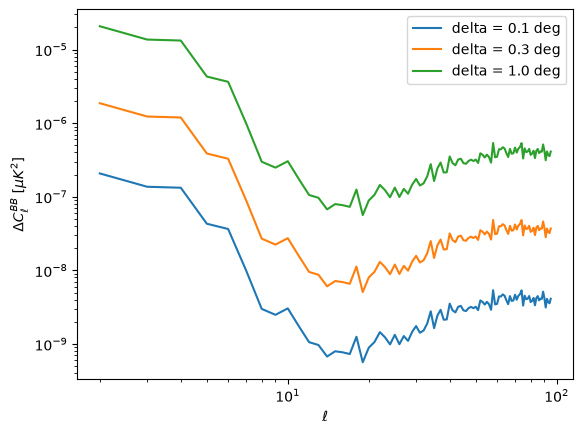

In [6]:
hmaps = sbm.HMaps.load_legacy("../tests/nside_32_boresight_hwp.h5")
cmb = hp.ud_grade(sbm.generate_cmb(128, r=0.0, cmb_seed=33), hmaps.nside)
sky32 = sbm.Sky.from_maps(*cmb)
basis = sbm.Basis.iqu(hwp=True)
ideal = sbm.map_make((hmaps, sy.sky_signal(sky32, hwp=True)), basis).iqu
ell = np.arange(3 * hmaps.nside)
for d_deg in (0.1, 0.3, 1.0):
    model = sy.sky_signal(sky32, hwp=True) + sy.polarization_angle(sky32, np.deg2rad(d_deg), hwp=True)
    residual = np.nan_to_num(sbm.map_make((hmaps, model), basis).iqu - ideal)
    plt.loglog(ell[2:], hp.anafast(residual)[2][2:], label=f"delta = {d_deg} deg")
plt.xlabel(r"$\ell$"); plt.ylabel(r"$\Delta C_\ell^{BB}$ [$\mu K^2$]"); plt.legend()

## Checklist

1. The perturbation as spin components, in the module of its stage (`sbm/systematics/`).
2. `@systematic(data=..., templates=...)` and the import in `sbm/systematics/__init__.py`.
3. A real-space TOD case in `tests/test_systematics.py` (and an `absorbed` case if it has templates).
4. A row in `docs/source/systematics.rst`, the function in `docs/source/reference.rst`, an entry in `CHANGELOG.md`.
5. `pytest` passes.

Signals that do not depend on the sky (emission of the optics or of the HWP) are constant
maps at $(0,0)$ or $(0,m)$; non-linear responses use the product of models,
`d + beta * (d * d)`; non-idealities of the HWP are harmonics of `sy.hwp_mueller`.